Pulling Financial Market Data...
Fetching market data from 2016-01-01 to 2026-07-29


/var/folders/2c/yb6xjdp11v57x1r5bk7tndtm0000gn/T/ipykernel_71545/359705254.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(tickers, start=start_date, end=end_date)['Close']



[                       0%                       ]
[                       0%                       ]


[**********************75%***********            ]  3 of 4 completed


[*********************100%***********************]  4 of 4 completed

Downsampling to uniform weekly frequency (Friday close)
Pulling OPEC+ Supply Data...


Merging into Master Matrix...

--- Dynamically Pulled Cleaned Weekly Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24    96.779999  89.309998       101.430000  18.700001   
2026-07-31    84.089996  79.260002       101.510002  18.670000   

            OPEC_Plus_Production  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  
2026-07-31             27.516865  
--- Summary Statistics ---
       Brent_Crude   WTI_Crude  US_Dollar_Index   VIX_Index  \
count   552.000000  552.000000       552.000000  552.000000   
mean     69.077319   64.734221        98.563678   18.318424   
std      18.298541   17.865778         4.895742    7.020733   
min      21.440001   16.940001   

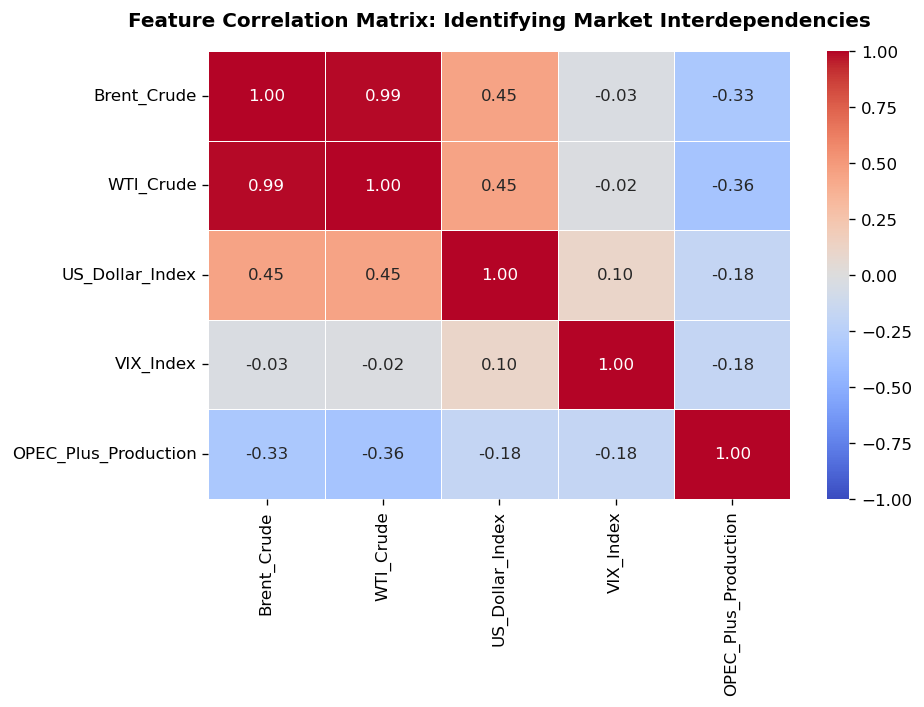

Normalization complete! New columns added to master_dataset.

--- Raw vs Normalized Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24    96.779999  89.309998       101.430000  18.700001   
2026-07-31    84.089996  79.260002       101.510002  18.670000   

            OPEC_Plus_Production  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  
2026-07-31             27.516865  

--- Smoothed Dataset (SMA, EMA and Rolling Median included) ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998

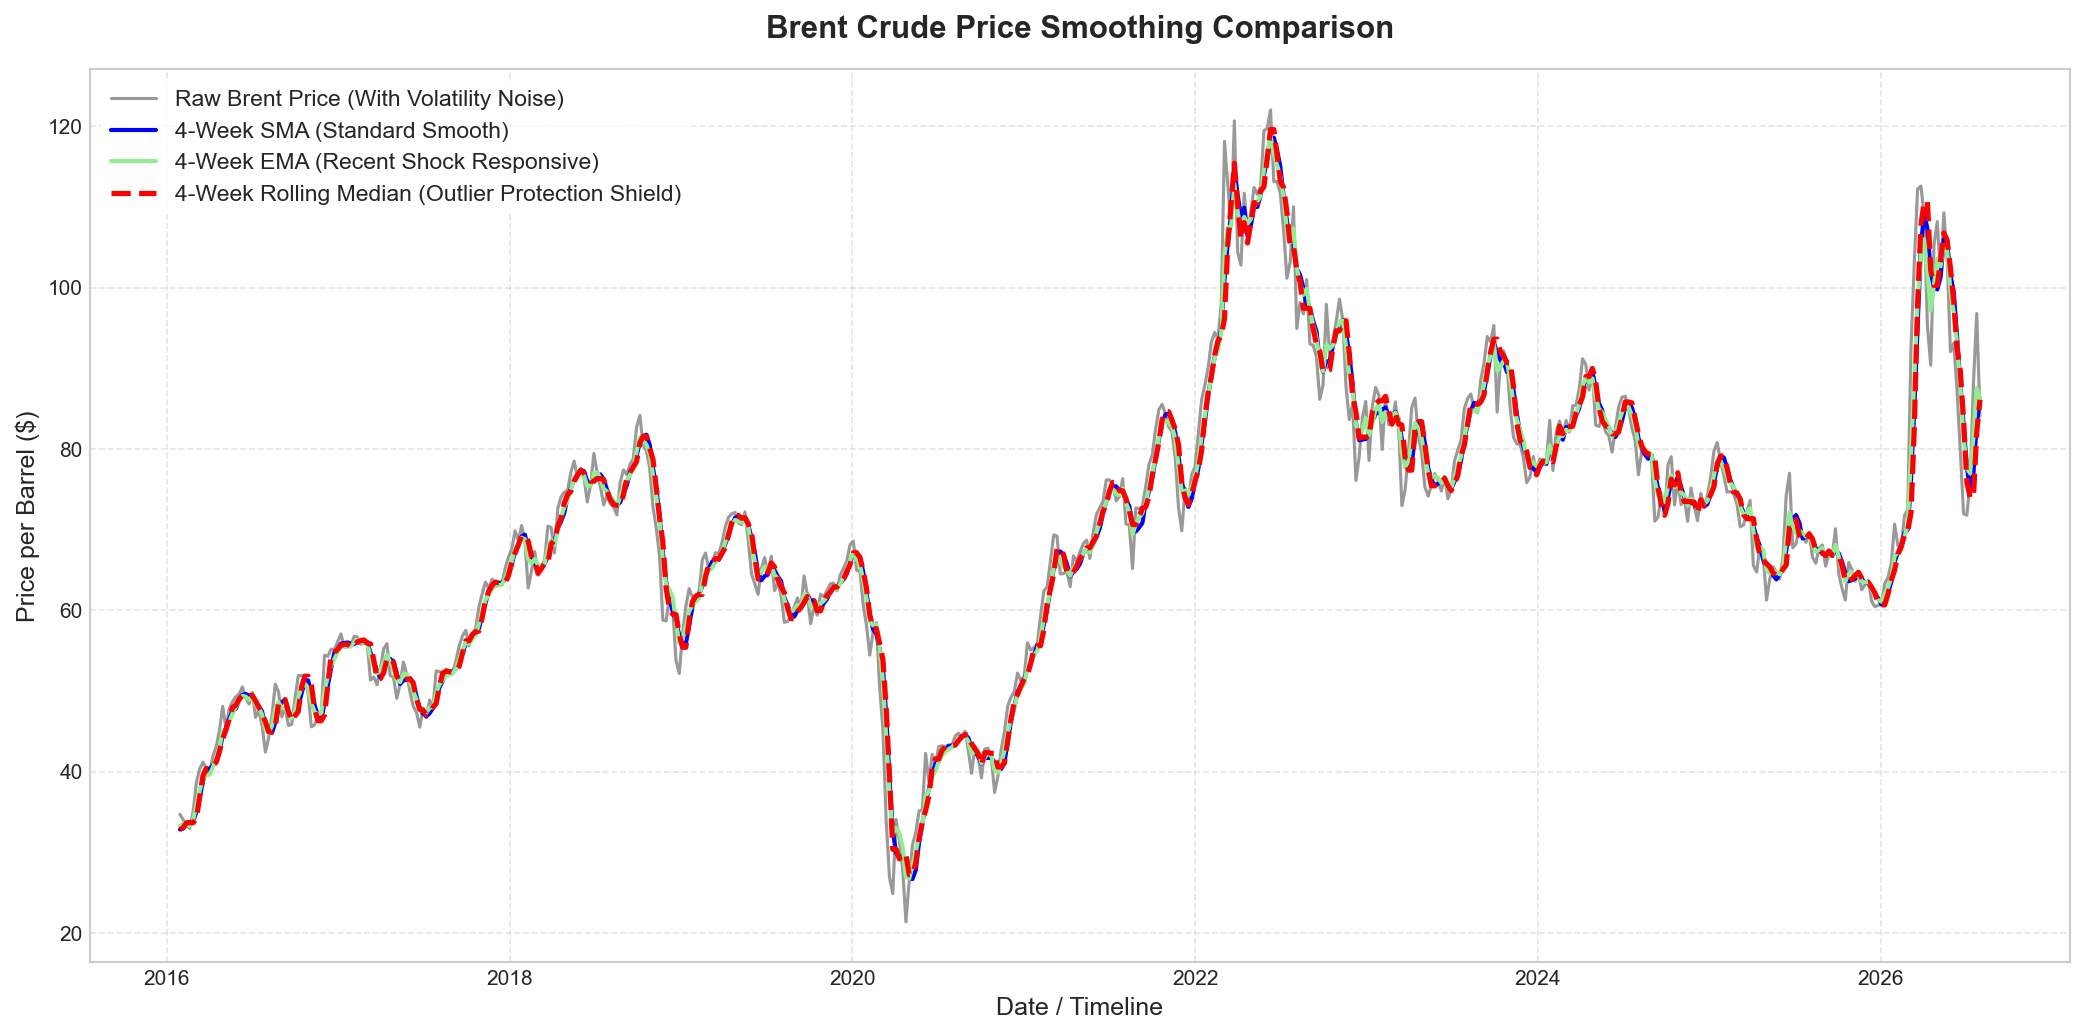

Brent Crude P-Value: 0.2336
-> Result: Brent Crude is Non-Stationary (Mountain). We must difference it for SARIMAX.
OPEC Supply P-Value: 0.4805
-> Result: OPEC Supply is Non-Stationary.


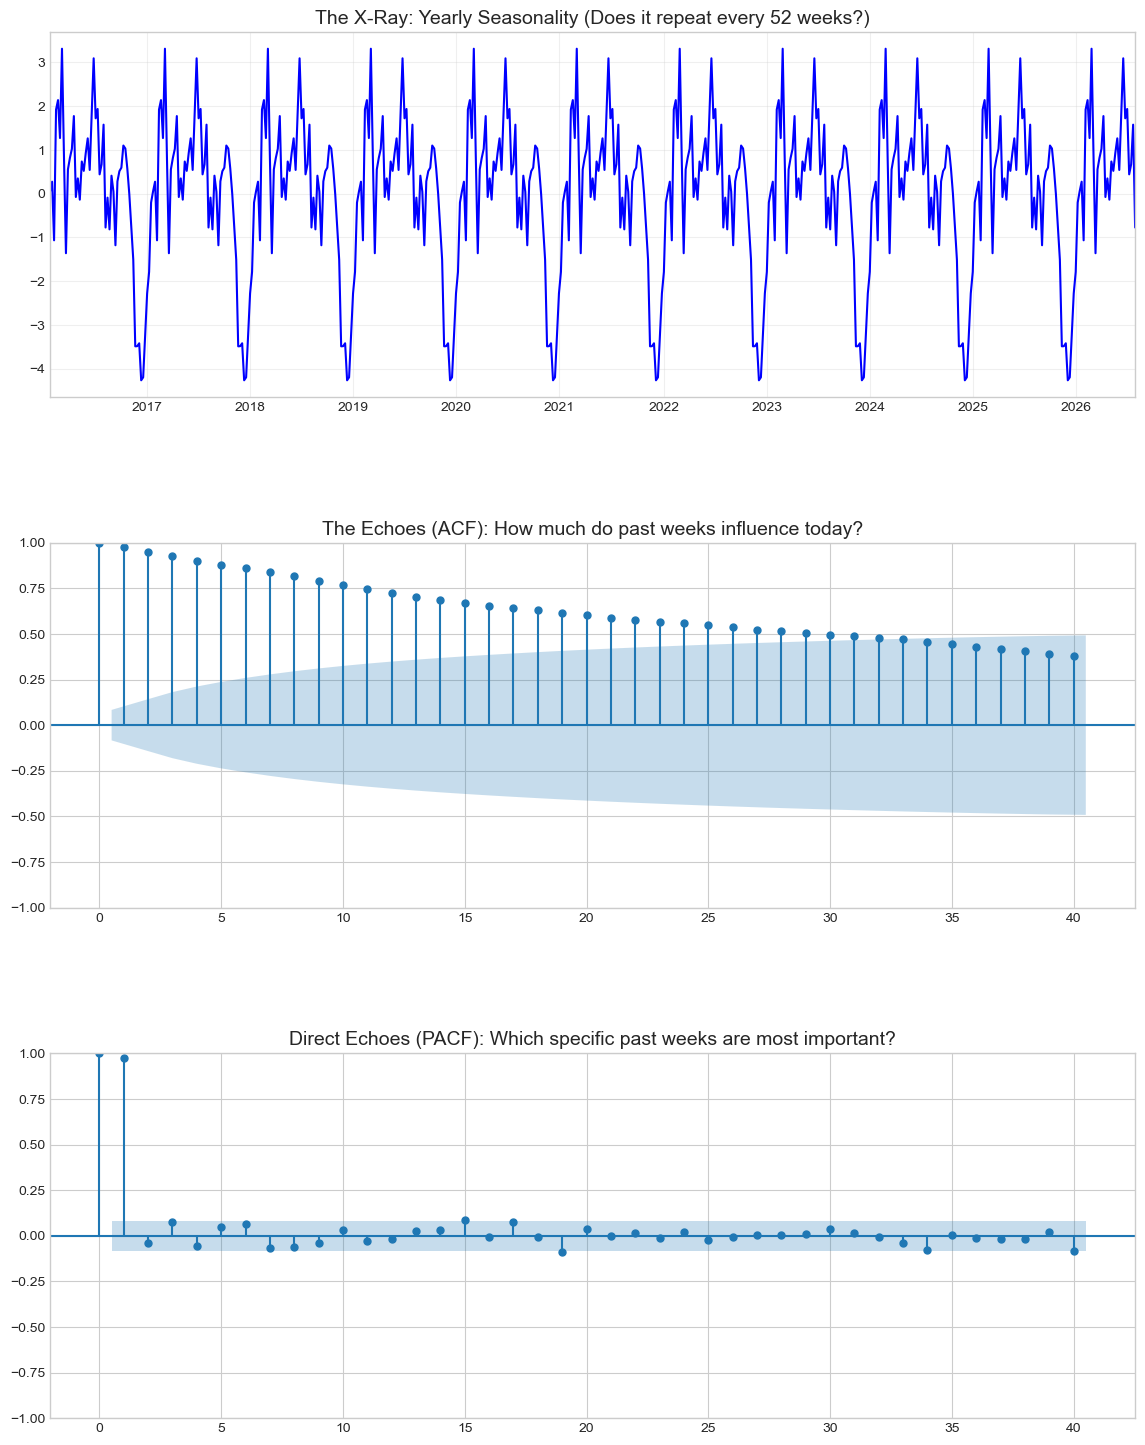

            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  OPEC_Plus_Production
2026-07-03        71.80      68.69           100.86      16.15                27.517
2026-07-10        76.01      71.41           100.97      15.03                27.517
2026-07-17        88.10      82.49           100.75      18.77                27.517
2026-07-24        96.78      89.31           101.43      18.70                27.517
2026-07-31        84.09      79.26           101.51      18.67                27.517


In [1]:
# --- RUN NOTEBOOK 1 TO GET THE DATA ---
%run data_collection_cleaning_EDA.ipynb

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
import xgboost as xgb

In [3]:
print("\n--- 1. ML FEATURE ENGINEERING (USING LOG NORMALIZATION) ---")
ml_df = master_dataset.copy()

# Create Lags
ml_df['Price_Lag_1'] = ml_df['Brent_Log'].shift(1)
ml_df['Price_Lag_2'] = ml_df['Brent_Log'].shift(2)
ml_df['Price_Lag_3'] = ml_df['Brent_Log'].shift(3)
ml_df = ml_df.dropna()

# Notice our target is now the Normalized Log column!
features = ['Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'USD_Z', 'VIX_Z', 'OPEC_Z']
target = 'Brent_Log' 

# Train/Test Split
train_size = int(len(ml_df) * 0.8)
train_data, test_data = ml_df.iloc[:train_size], ml_df.iloc[train_size:]

X_train, y_train_log = train_data[features], train_data[target]
X_test, y_test_log = test_data[features], test_data[target]

# We keep the raw dollars just to calculate our final accuracy scores
y_test_dollars = test_data['Brent_Crude']

print(f"Data Ready: {len(X_train)} Train Rows, {len(X_test)} Test Rows.")


--- 1. ML FEATURE ENGINEERING (USING LOG NORMALIZATION) ---
Data Ready: 436 Train Rows, 110 Test Rows.


In [4]:
print("\n--- 2. TRAINING MULTIPLE ALGORITHMS ---")
# 1. LASSO Regression (Great for stripping out useless features)
lasso_model = Lasso(alpha=0.01, random_state=42)
lasso_model.fit(X_train, y_train_log)

# 2. Random Forest (Great for general non-linear relationships)
rf_model = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
rf_model.fit(X_train, y_train_log)

# 3. XGBoost (The reigning champion from our previous test)
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
xgb_model.fit(X_train, y_train_log)


--- 2. TRAINING MULTIPLE ALGORITHMS ---


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [5]:
print("\n--- 3. CONVERTING PREDICTIONS BACK TO DOLLARS ---")
# Predict in Log Space, then use expm1 to convert back to real dollars
preds_lasso = np.expm1(lasso_model.predict(X_test))
preds_rf = np.expm1(rf_model.predict(X_test))
preds_xgb = np.expm1(xgb_model.predict(X_test))


--- 3. CONVERTING PREDICTIONS BACK TO DOLLARS ---


In [6]:
print("\n--- 4. AT-A-GLANCE COMPARISON TABLE ---")
import os
def get_metrics(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return {"Model": model_name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "R2": round(r2, 4)}

model_list = [
    {"Model": "SARIMAX (Baseline)", "MAE": 11.29, "RMSE": 13.03, "R2": -0.0851}, 
    get_metrics(y_test_dollars, preds_lasso, "LASSO Regression"),
    get_metrics(y_test_dollars, preds_rf, "Random Forest"),
    get_metrics(y_test_dollars, preds_xgb, "XGBoost")
]

if os.path.exists('../data_processed/lstm_test_predictions.csv'):
    lstm_preds_df = pd.read_csv('../data_processed/lstm_test_predictions.csv', index_col=0)
    mae_lstm = mean_absolute_error(lstm_preds_df['Actual_Brent'], lstm_preds_df['LSTM_Pred'])
    rmse_lstm = np.sqrt(mean_squared_error(lstm_preds_df['Actual_Brent'], lstm_preds_df['LSTM_Pred']))
    r2_lstm = r2_score(lstm_preds_df['Actual_Brent'], lstm_preds_df['LSTM_Pred'])
    model_list.append({"Model": "LSTM (Deep Learning)", "MAE": round(mae_lstm, 2), "RMSE": round(rmse_lstm, 2), "R2": round(r2_lstm, 4)})

results_df = pd.DataFrame(model_list)
display(results_df)



--- 4. AT-A-GLANCE COMPARISON TABLE ---


,Model,MAE,RMSE,R2
0,SARIMAX (Baseline),11.29,13.03,-0.0851
1,LASSO Regression,3.34,5.22,0.8238
2,Random Forest,3.54,5.18,0.8262
3,XGBoost,3.61,5.07,0.8336
4,LSTM (Deep Learning),4.87,7.66,0.6204



--- 5. VISUALIZING THE COMPARISON ---


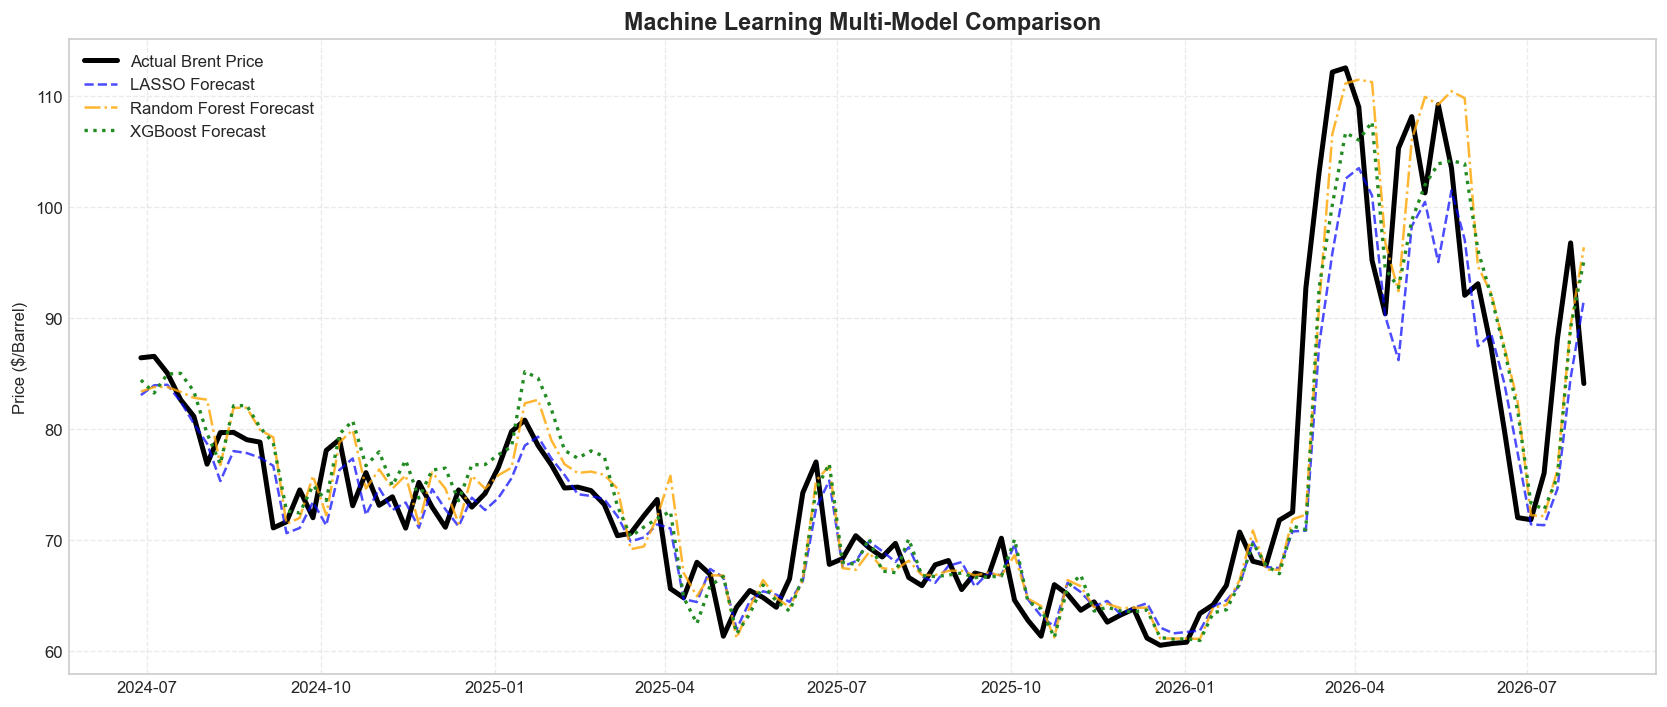

In [7]:
print("\n--- 5. VISUALIZING THE COMPARISON ---")
plt.figure(figsize=(14, 6), dpi=120)
plt.plot(test_data.index, y_test_dollars, label='Actual Brent Price', color='black', linewidth=3)

# Plotting the three ML models
plt.plot(test_data.index, preds_lasso, label='LASSO Forecast', color='blue', linestyle='--', alpha=0.7)
plt.plot(test_data.index, preds_rf, label='Random Forest Forecast', color='orange', linestyle='dashdot', alpha=0.8)
plt.plot(test_data.index, preds_xgb, label='XGBoost Forecast', color='forestgreen', linestyle=':', linewidth=2)

plt.title('Machine Learning Multi-Model Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Price ($/Barrel)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

/var/folders/2c/yb6xjdp11v57x1r5bk7tndtm0000gn/T/ipykernel_71545/3442921334.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='MAE', palette='Reds_r', ax=axes[0])
/var/folders/2c/yb6xjdp11v57x1r5bk7tndtm0000gn/T/ipykernel_71545/3442921334.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='R2', palette='Greens', ax=axes[1])


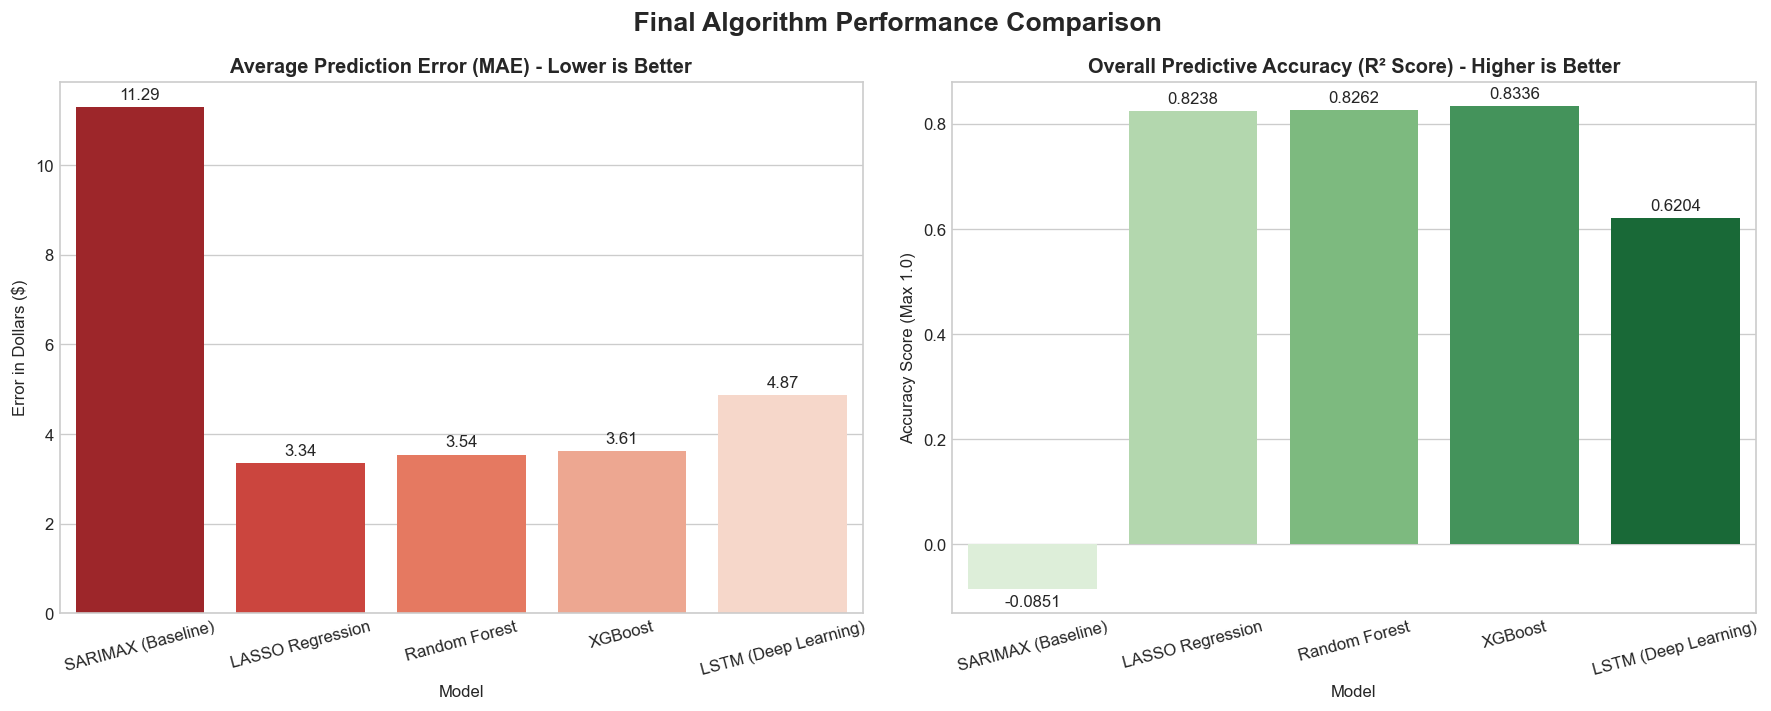

In [8]:
import seaborn as sns

# Set up the figure with two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# Plot 1: Mean Absolute Error (Lower is Better)
sns.barplot(data=results_df, x='Model', y='MAE', palette='Reds_r', ax=axes[0])
axes[0].set_title('Average Prediction Error (MAE) - Lower is Better', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Error in Dollars ($)')
axes[0].tick_params(axis='x', rotation=15)
# Add value labels on top of bars
for i in axes[0].containers:
    axes[0].bar_label(i, padding=3)

# Plot 2: R-Squared Score (Higher is Better)
# We clip the bottom at 0 just so the negative scores don't warp the chart too badly
sns.barplot(data=results_df, x='Model', y='R2', palette='Greens', ax=axes[1])
axes[1].set_title('Overall Predictive Accuracy (R² Score) - Higher is Better', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Accuracy Score (Max 1.0)')
axes[1].tick_params(axis='x', rotation=15)
for i in axes[1].containers:
    axes[1].bar_label(i, padding=3)

plt.suptitle(' Final Algorithm Performance Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()